# 遅延(むだ時間)

入力を、形を変えずに**決まった時間だけ遅らせて**出す回路です。ギターのエコーやコーラスに使われたバケツリレー素子(BBD)、長いケーブル、配管の中を流れる液体の温度(ヒーターから温度計まで流れるあいだの遅れ)など、身のまわりの多くのものに「むだ時間」があります。制御では、むだ時間があると系が不安定になりやすいことが知られています。

この回では、波形がそのまま遅れること、1 周期より長い遅れが見分けられないこと、そしてボード線図で「ゲインは 1 のまま、位相だけが周波数に比例して遅れる」ことを見ます。

## 回路

![バケツリレー素子(BBD)](05_delay/circuit.svg)

バケツリレー素子は、スイッチとコンデンサを長く並べたものです。2 つのクロック φ1、φ2 で交互にスイッチを閉じ、電荷(電圧)をとなりのコンデンサへバケツリレーのように受けわたします。段の数を N、クロックの周期を T とすると、入力は N × T だけ遅れて出てきます。Mimic の遅延は、4096 段の BBD を 5 µs のクロックで動かしたものにあたります(Mimic の中ではデジタルの記憶で作っています)。

## 原理

出力は、入力を $\tau$ だけずらしたものです。

$$V_\mathrm{out}(t) = V_\mathrm{in}(t - \tau)$$

| 入力 | 出力 |
|---|---|
| どんな波形でも | 同じ形のまま $\tau$ だけ遅れる |
| 正弦波(周波数 f) | 振幅はそのまま(ゲイン 1)、位相が $-360\,f\tau$ 度遅れる |

周波数で見ると、**ゲインはどの周波数でも 1(0 dB)で、位相は周波数に比例して遅れます**。周波数を横軸に普通の目盛り(対数でない)でとると、位相は傾き $-360\tau$ の直線になります。2 章のオールパスフィルタ(2-4)もゲイン 1 で位相だけ変わりましたが、位相の遅れは −180° で止まりました。むだ時間の位相は、周波数とともにどこまでも遅れていきます。

位相は 360° ごとに同じに見えるので、周期的な波形では、1 周期より長い遅れと短い遅れを見分けられません(例:周期 10 ms の波を 12 ms 遅らせると、2 ms 遅れたものと同じに見える)。

![むだ時間(模式図)](05_delay/response.svg)

## Mimic の設定と回路定数

| Mimic(Python) | ライブラリ(Arduino) | 回路 |
|---|---|---|
| `lab.mimic.delay(n)` | `mimic.setDigitalDelay(n)` | 段の数 N(サンプル数)。遅れは N × 5 µs、0〜4095(最大 20.475 ms) |

- 1 ms は 200 サンプルです。下の準備のセルの `samples(ms)` で、ms からサンプル数に直します。
- 遅れを 0 にしても、Mimic と測定器にはもともと約 0.05 ms の遅れがあります(2-3 で測った、入力のフィルタと計算と信号発生器の階段のぶん)。測った遅れは、設定より 0.05 ms ほど長くなります。

## 準備:測定器につなぐ

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from mimiclab import MimicLab, fit_sine, match_phase, plot_waveforms

lab = MimicLab()  # finds the Arduino; or MimicLab("COM5")
lab

MimicLab(port='COM4', ver=0.1.3, mimic=20261125)

In [2]:
def show(t, ch1, ch2, label):
    fig, ax = plt.subplots(figsize=(8, 3.5))
    ax.plot(t * 1e3, ch1, label="CH1: input")
    ax.plot(t * 1e3, ch2, label=f"CH2: output ({label})")
    ax.set_xlabel("Time [ms]")
    ax.set_ylabel("Voltage [V]")
    ax.grid(True)
    ax.legend(loc="upper right")
    plt.show()


def samples(ms):
    # The delay is set in module samples (5 us): 200 per ms, at most 4095
    return min(round(ms * 200), 4095)


def lag_ms(t, ch1, ch2):
    # How much CH2 lags CH1 (ms), from the best match of the two (cross-correlation)
    n = len(t)
    lags = np.arange(-(n - 1), n)
    c = np.correlate(ch2 - ch2.mean(), ch1 - ch1.mean(), "full") / (n - np.abs(lags))  # per point
    c[np.abs(lags) > n // 2] = -np.inf   # at least half of the capture overlaps
    # A repeating wave matches as well one period later: take the smallest shift
    peak = np.r_[False, (c[1:-1] >= c[:-2]) & (c[1:-1] >= c[2:]), False]
    best = np.flatnonzero(peak & (c >= 0.9 * c.max()))
    return lags[best[np.argmin(np.abs(lags[best]))]] * (t[1] - t[0]) * 1e3

## 実験 1:波形がそのまま遅れる

50 Hz、振幅 1 V の方形波を、5 ms 遅らせます。出力は同じ形のまま 5 ms 右にずれるはずです。遅れは、CH1 と CH2 をずらしながら重ね合わせ、いちばんよく重なるずらし量(相互相関)から測ります。

measured lag 5.05 ms (setting 5.000 ms, plus about 0.05 ms)


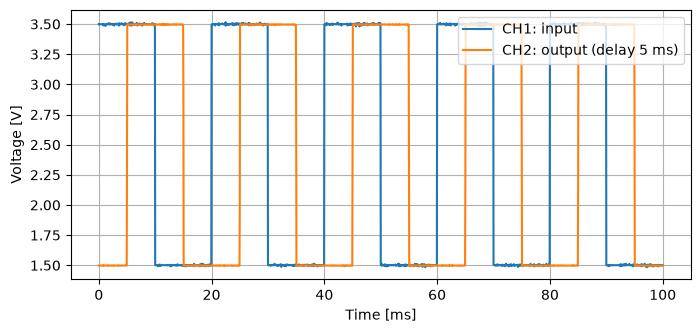

In [3]:
DELAY_MS = 5

lab.fg.square(50, 1.0)
lab.mimic.delay(samples(DELAY_MS))
time.sleep(0.1)
t, ch1, ch2 = lab.scope.capture(2000)   # 0.1 s
print(f"measured lag {lag_ms(t, ch1, ch2):.2f} ms (setting {samples(DELAY_MS) / 200:.3f} ms, plus about 0.05 ms)")
show(t, ch1, ch2, f"delay {DELAY_MS} ms")

取り込みは 50 µs(0.05 ms)ごとなので、測った遅れも 0.05 ms きざみです。

## 実験 2:1 周期より長い遅れ

100 Hz(周期 10 ms)の正弦波を、12 ms 遅らせます。波形を見ても、相互相関で測っても、2 ms しか遅れていないように見えるはずです。

measured lag 2.00 ms (setting 12 ms = 1 period + 2 ms)


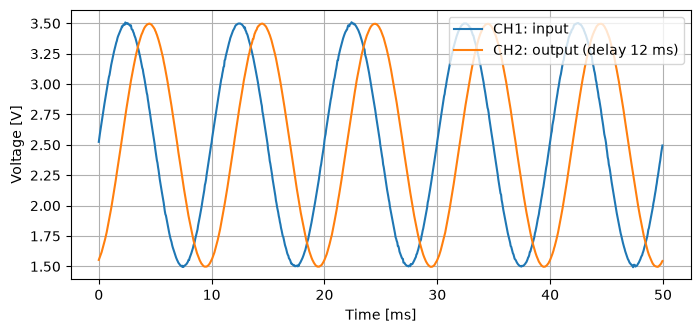

In [4]:
DELAY_MS = 12

lab.fg.sine(100, 1.0)
lab.mimic.delay(samples(DELAY_MS))
time.sleep(0.1)
t, ch1, ch2 = lab.scope.capture(1000)   # 50 ms
print(f"measured lag {lag_ms(t, ch1, ch2):.2f} ms (setting {DELAY_MS} ms = 1 period + {DELAY_MS - 10} ms)")
show(t, ch1, ch2, f"delay {DELAY_MS} ms")

くり返す波形では、1 周期ずれると元と同じ形に戻るので、何周期遅れたかはわかりません。本当の遅れを測るには、1 回だけの変化(段差やパルス)を入れて、出力に現れるまでの時間を測ります。

## 実験 3:ボード線図

遅れを 1 ms にして、20 Hz〜1 kHz の周波数特性を測ります。ゲインはどこでも 0 dB、位相は 1 kHz で −360°(1 回転)遅れるはずです。周波数の目盛りは対数でなく普通の目盛りにして、位相が直線になることを確かめます。直線の傾きから遅れを求めます。

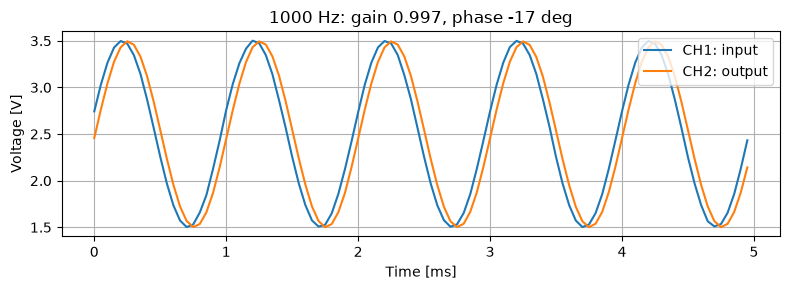

In [5]:
DELAY_MS = 1
freqs = np.linspace(20, 1000, 25)

lab.mimic.delay(samples(DELAY_MS))
r = lab.frequency_response(freqs, amp=1.0, monitor=True)

各周波数で取り込んだ波形です(クリックで開きます)。


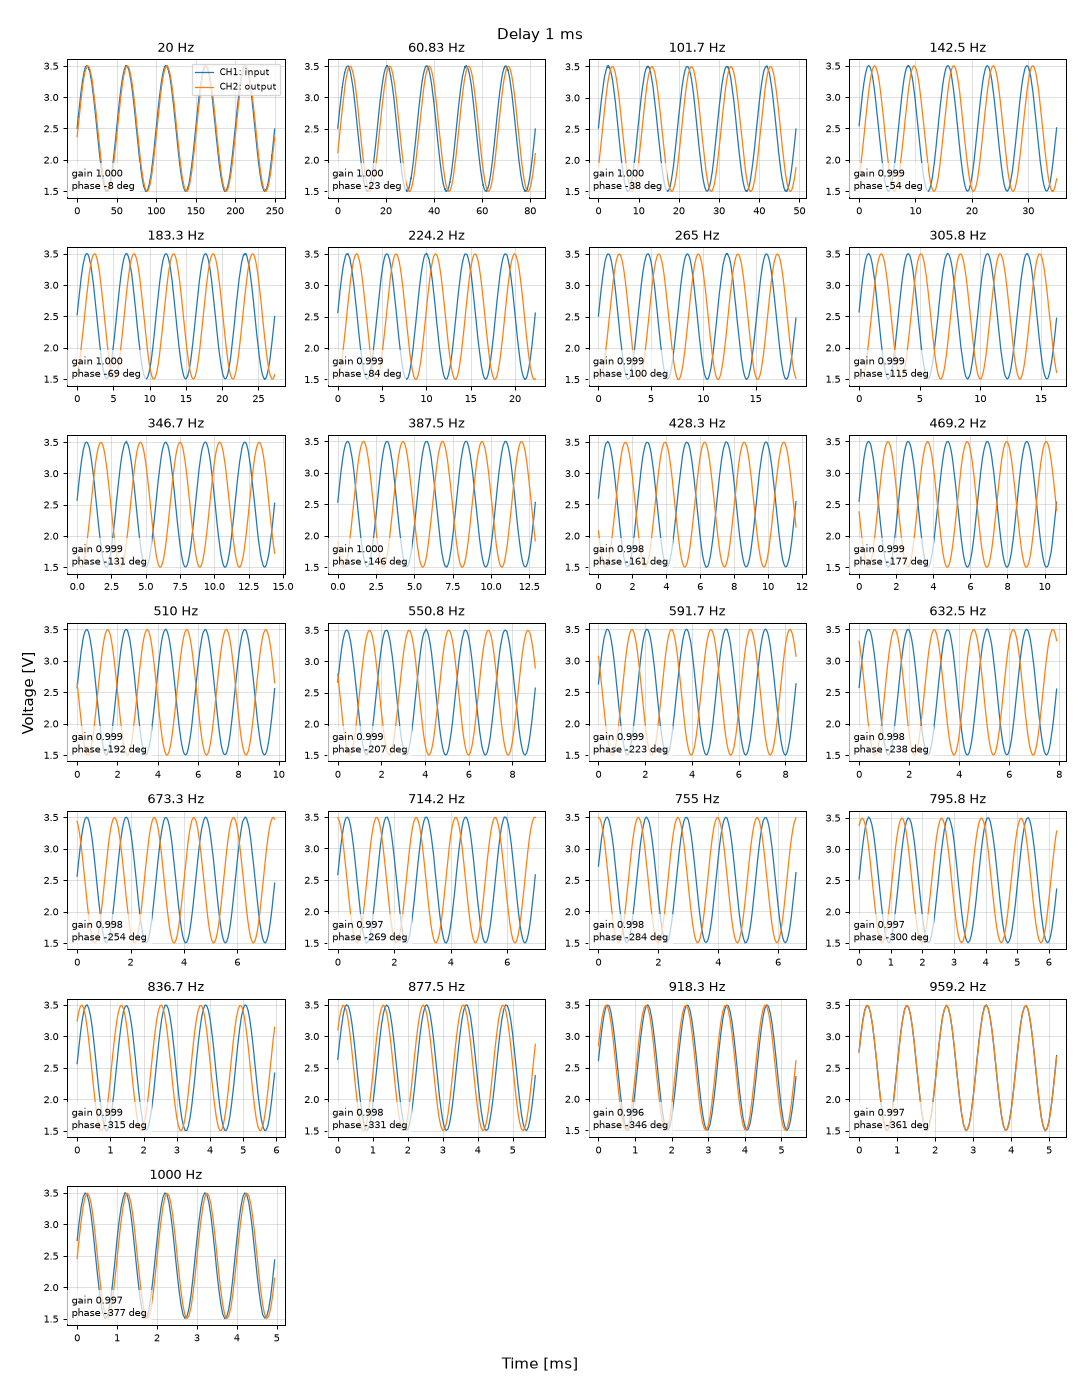

In [6]:
plot_waveforms(r, title=f"Delay {DELAY_MS} ms", collapsed=True)

from the slope of the phase: 1.046 ms (setting 1.000 ms, plus about 0.05 ms)


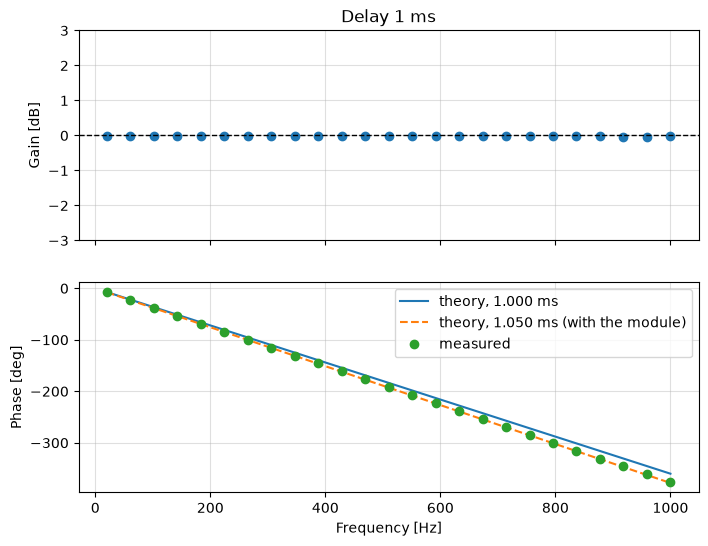

In [7]:
tau = samples(DELAY_MS) / 200e3   # s
phase = match_phase(r.phase, -360 * r.freq * tau)
slope = np.polyfit(r.freq, phase, 1)[0]
print(f"from the slope of the phase: {-slope / 360 * 1e3:.3f} ms (setting {tau * 1e3:.3f} ms, plus about 0.05 ms)")

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 6), sharex=True)
ax1.plot(r.freq, r.gain_db, "o")
ax1.axhline(0, color="k", ls="--", lw=1)
ax1.set_ylim(-3, 3)
ax2.plot(r.freq, -360 * r.freq * tau, "-", label=f"theory, {tau * 1e3:.3f} ms")
ax2.plot(r.freq, -360 * r.freq * (tau + 0.05e-3), "--", label=f"theory, {tau * 1e3 + 0.05:.3f} ms (with the module)")
ax2.plot(r.freq, phase, "o", label="measured")
ax1.set_title(f"Delay {DELAY_MS} ms")
ax1.set_ylabel("Gain [dB]")
ax2.set_ylabel("Phase [deg]")
ax2.set_xlabel("Frequency [Hz]")
for ax in (ax1, ax2):
    ax.grid(True, alpha=0.4)
ax2.legend()
plt.show()

ゲインは周波数によらず 0 dB のまま、位相は周波数に比例して遅れます。傾きから求めた遅れは、設定に Mimic と測定器のもともとの遅れ(約 0.05 ms)を足したものになります。2-3 でバイパスのボード線図から測った遅れと同じものです。

## やってみよう

下のセルの値(大文字の名前)を**1 つずつ**変えて実行し、オシロの波形と数値がどう変わるかを自分の目で確かめましょう。どの値を順に試すとよいかと、何が見えるはずかは「ヒント」に書いてあります。

> Run All で最後まで実行したあと(接続を閉じたあと)にやるときは、最初の「測定器につなぐ」のセルをもう一度実行してから始めます。

### 1. 遅れを変える

50 Hz の方形波のまま、遅れを変えます。
<details><summary>ヒント</summary>

`DELAY_MS` を 1 → 10 → 20 と変えてみましょう(実験 1 は 5)。方形波の周期は 20 ms です。

- 1 ms:わずかに右にずれます。
- 10 ms(半周期):出力は入力をひっくり返したように見えます。測った遅れは −10 ms と出ることもあります(+10 ms と区別できないため)。
- 20 ms(1 周期):出力は入力とほぼ重なり、遅れていないように見えます。

</details>

measured lag 1.05 ms (setting 1.000 ms)


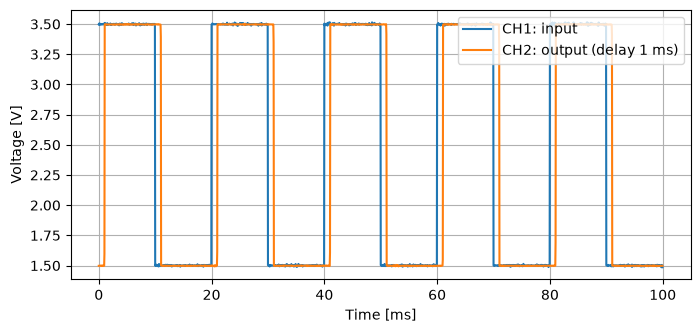

In [8]:
DELAY_MS = 1

lab.fg.square(50, 1.0)
lab.mimic.delay(samples(DELAY_MS))
time.sleep(0.1)
t, ch1, ch2 = lab.scope.capture(2000)
print(f"measured lag {lag_ms(t, ch1, ch2):.2f} ms (setting {samples(DELAY_MS) / 200:.3f} ms)")
show(t, ch1, ch2, f"delay {DELAY_MS} ms")

### 2. 同じ遅れで周波数を変える

遅れを 2.5 ms にしたまま、正弦波の周波数を変えて、位相の遅れを見ます。
<details><summary>ヒント</summary>

`FREQ` を 100 → 200 → 400 → 50 と変えてみましょう。位相の遅れは 360 × f × 2.5 ms で、90°、180°、360°、45° です(実際には 0.05 ms のぶん少し多くなります)。

- 200 Hz:180° 遅れて、出力は入力をひっくり返した形になります。
- 400 Hz:360° 遅れて、出力は入力とぴったり重なります。

同じ遅れでも、周波数が高いほど位相の遅れは大きくなります。

</details>

phase of the output: -91 deg (-360 x 100 Hz x 2.55 ms = -92 deg, in -180 - 180)


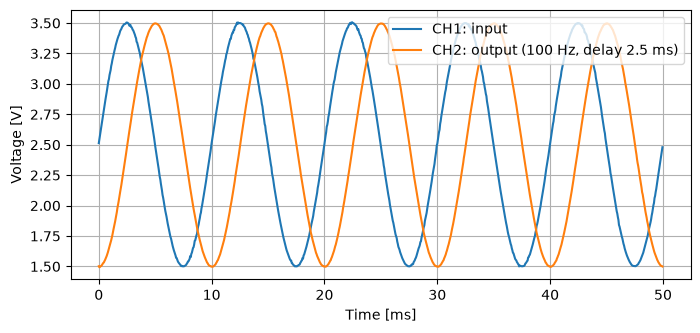

In [9]:
FREQ = 100

lab.fg.sine(FREQ, 1.0)
lab.mimic.delay(samples(2.5))
time.sleep(0.1)
t, ch1, ch2 = lab.scope.capture(1000)   # 50 ms
p = (fit_sine(t, ch2, FREQ)[1] - fit_sine(t, ch1, FREQ)[1] + 180) % 360 - 180
expected = (-360 * FREQ * 2.55e-3 + 180) % 360 - 180
print(f"phase of the output: {p:.0f} deg (-360 x {FREQ} Hz x 2.55 ms = {expected:.0f} deg, in -180 - 180)")
show(t, ch1, ch2, f"{FREQ} Hz, delay 2.5 ms")

## まとめ

- むだ時間(遅延)は、入力を形を変えずに $\tau$ だけ遅らせる。バケツリレー素子(BBD)は、スイッチとコンデンサの列で電荷を受けわたして遅らせる。
- 周波数で見ると、ゲインはどこでも 1、位相は $-360 f\tau$ 度で、周波数に比例してどこまでも遅れる。
- くり返す波形では、1 周期より長い遅れは見分けられない。
- Mimic では `delay(n)`(n × 5 µs、最大 20.475 ms)。Mimic と測定器には、もともと約 0.05 ms の遅れがある。

最後に Mimic を素通し(バイパス)に戻して、接続を閉じます。

In [10]:
lab.mimic.bypass()
lab.fg.sine(100, 1.0)
lab.close()